# Future Interns – Machine Learning Task 03
## AI-Powered Resume Screening & Candidate Ranking System

**Objective:** clean resume text, extract relevant skills, compare resumes with a job description, rank candidates, and identify missing skills.

**Approach:** explainable skill-dictionary matching + TF-IDF + cosine similarity. This is a decision-support prototype, not an automated hiring decision-maker.

## 1. Install and import libraries

If a library is missing, uncomment the installation command and run it in a notebook cell.

In [18]:
import re
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option('display.max_colwidth', 120)
print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Load the resume dataset

Download the Kaggle Resume Dataset and place `Resume.csv` in a folder named `dataset` beside this notebook. The common dataset has columns such as `ID`, `Resume_str`, `Resume_html`, and `Category`. This cell detects common resume-text column names.

In [19]:

df = pd.read_csv("/content/customer_support_tickets.csv")
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
display(df.head())

Dataset shape: (8469, 17)
Columns: ['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciat...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine unt...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any da...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


## 3. Inspect and prepare the data

We identify the resume-text column and optional category column. Category is retained for inspection only; it is not used as a hiring score.

In [20]:
text_candidates = ['Resume_str', 'Resume', 'resume', 'resume_text', 'text', 'Ticket Description', 'Ticket Subject']
category_candidates = ['Category', 'category', 'Job_Role', 'role', 'Ticket Type']

TEXT_COL = next((col for col in text_candidates if col in df.columns), None)
CATEGORY_COL = next((col for col in category_candidates if col in df.columns), None)

if TEXT_COL is None:
    raise ValueError(f'No suitable text column found. Available columns: {df.columns.tolist()}')

print('Selected text column:', TEXT_COL)
print('Selected category column:', CATEGORY_COL)
print('\nMissing values:')
display(df.isnull().sum())

working_df = df[[TEXT_COL] + ([CATEGORY_COL] if CATEGORY_COL else [])].copy()
working_df = working_df.dropna(subset=[TEXT_COL])
working_df[TEXT_COL] = working_df[TEXT_COL].astype(str)
working_df = working_df[working_df[TEXT_COL].str.strip().ne('')]
working_df = working_df.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)

print('Usable rows:', len(working_df))
display(working_df.head(3))

Selected text column: Ticket Description
Selected category column: Ticket Type

Missing values:


,0
Ticket ID,0
Customer Name,0
Customer Email,0
Customer Age,0
Customer Gender,0
Product Purchased,0
Date of Purchase,0
Ticket Type,0
Ticket Subject,0
Ticket Description,0


Usable rows: 8077


,Ticket Description,Ticket Type
0,I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciat...,Technical issue
1,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'...,Technical issue
2,I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine unt...,Technical issue


## 4. Text cleaning and preprocessing

We lowercase text, remove URLs and email addresses, normalize punctuation/spacing, and preserve useful technical characters such as `C++`, `C#`, and `+`.

In [21]:
def clean_text(text):
    """Clean resume or job-description text without deleting useful skill symbols."""
    if pd.isna(text):
        return ''
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = text.replace('\u2013', '-').replace('\u2014', '-')
    text = re.sub(r'[^a-z0-9+#./\s-]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

working_df['clean_resume'] = working_df[TEXT_COL].apply(clean_text)
print('Original resume:')
print(working_df.loc[0, TEXT_COL][:500])
print('\nCleaned resume:')
print(working_df.loc[0, 'clean_resume'][:500])

Original resume:
I'm having an issue with the {product_purchased}. Please assist.

Your billing zip code is: 71701.

We appreciate that you have requested a website address.

Please double check your email address. I've tried troubleshooting steps mentioned in the user manual, but the issue persists.

Cleaned resume:
i m having an issue with the product purchased . please assist. your billing zip code is 71701. we appreciate that you have requested a website address. please double check your email address. i ve tried troubleshooting steps mentioned in the user manual but the issue persists.


## 5. Define the skill dictionary

This is an editable starter vocabulary. Expand it for the roles you want to screen. Skill extraction is dictionary-based and explainable; it may miss synonyms or skills not listed here.

In [22]:
SKILL_GROUPS = {
    'programming': ['python', 'r', 'java', 'c++', 'javascript'],
    'data_analysis': [
        'sql', 'excel', 'advanced excel', 'power bi', 'tableau',
        'pandas', 'numpy', 'matplotlib', 'seaborn', 'statistics',
        'data analysis', 'data visualization'
    ],
    'machine_learning': [
        'machine learning', 'deep learning', 'scikit-learn',
        'tensorflow', 'pytorch', 'natural language processing',
        'nlp', 'computer vision', 'model evaluation'
    ],
    'databases_and_tools': [
        'mysql', 'postgresql', 'mongodb', 'git', 'github',
        'jupyter', 'jupyter notebook', 'vs code', 'streamlit'
    ],
    'cloud_and_big_data': ['aws', 'azure', 'google cloud', 'spark', 'hadoop']
}

ALL_SKILLS = sorted(
    {skill for group in SKILL_GROUPS.values() for skill in group},
    key=len,
    reverse=True
)

def extract_skills(text, skill_list=None):
    """Find listed skills using boundary-aware matching."""
    cleaned = clean_text(text)
    skill_list = skill_list or ALL_SKILLS
    found = []
    for skill in skill_list:
        escaped = re.escape(skill.lower()).replace(r'\ ', r'\s+')
        pattern = rf'(?<![a-z0-9+#]){escaped}(?![a-z0-9+#])'
        if re.search(pattern, cleaned):
            found.append(skill)
    return sorted(set(found))

working_df['extracted_skills'] = working_df[TEXT_COL].apply(extract_skills)
display(working_df[[TEXT_COL, 'extracted_skills']].head(5))

,Ticket Description,extracted_skills
0,I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciat...,[]
1,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'...,[]
2,I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine unt...,[]
3,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I...,[]
4,I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any da...,[]


## 6. Enter the target job description

Edit the job description below for the role you want to screen. You can also provide a curated required-skills list. A manually reviewed list is usually more reliable than automatically detecting every requirement from free text.

In [23]:
job_description = """
We are looking for an entry-level Data Analyst.
Required skills: Python, SQL, Excel, Power BI, Statistics, Machine Learning.
The candidate should be comfortable with data cleaning, data analysis,
data visualization, pandas and numpy.
"""

# Recommended: review and edit this list to match the actual job requirements.
required_skills = [
    'python', 'sql', 'excel', 'power bi',
    'statistics', 'machine learning', 'pandas', 'numpy'
]

required_skills = sorted({skill.lower().strip() for skill in required_skills})
cleaned_job_description = clean_text(job_description)

print('Required skills:', required_skills)
print('\nCleaned job description:')
print(cleaned_job_description)

Required skills: ['excel', 'machine learning', 'numpy', 'pandas', 'power bi', 'python', 'sql', 'statistics']

Cleaned job description:
we are looking for an entry-level data analyst. required skills python sql excel power bi statistics machine learning. the candidate should be comfortable with data cleaning data analysis data visualization pandas and numpy.


## 7. Extract skills from each resume

We compare the skills found in each resume with the required skills for the selected role.

In [24]:
working_df['candidate_skills'] = working_df[TEXT_COL].apply(extract_skills)
working_df['matched_skills'] = working_df['candidate_skills'].apply(
    lambda skills: sorted(set(skills).intersection(required_skills))
)
working_df['missing_skills'] = working_df['candidate_skills'].apply(
    lambda skills: sorted(set(required_skills) - set(skills))
)

display(working_df[['candidate_skills', 'matched_skills', 'missing_skills']].head(10))

,candidate_skills,matched_skills,missing_skills
0,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
1,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
2,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
3,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
4,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
5,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
6,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
7,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
8,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
9,[],[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"


## 8. Calculate TF-IDF and cosine similarity

TF-IDF converts text into numerical vectors. Cosine similarity measures the textual similarity between each resume and the job description. It is a text similarity measure, not a probability of being hired or a measure of future job performance.

In [25]:
documents = [cleaned_job_description] + working_df['clean_resume'].tolist()

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words='english',
    max_features=10000
)

tfidf_matrix = vectorizer.fit_transform(documents)
similarity_scores = cosine_similarity(
    tfidf_matrix[0:1], tfidf_matrix[1:]
).flatten()

working_df['similarity_score'] = similarity_scores * 100
print('TF-IDF matrix shape:', tfidf_matrix.shape)
display(working_df[['similarity_score']].head())

TF-IDF matrix shape: (8078, 10000)


,similarity_score
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0


## 9. Calculate skill-match and final scores

Starter scoring formula:

`Final Score = 70% × Skill Match Score + 30% × TF-IDF Similarity Score`

Both component scores are on a 0–100 scale. These weights are design choices for this prototype, not scientifically validated hiring weights.

In [26]:
SKILL_WEIGHT = 0.70
SIMILARITY_WEIGHT = 0.30

if not np.isclose(SKILL_WEIGHT + SIMILARITY_WEIGHT, 1.0):
    raise ValueError('Scoring weights must add up to 1.0')

if len(required_skills) == 0:
    raise ValueError('Add at least one required skill before scoring.')

working_df['skill_match_score'] = working_df['matched_skills'].apply(
    lambda skills: len(skills) / len(required_skills) * 100
)

working_df['final_match_score'] = (
    SKILL_WEIGHT * working_df['skill_match_score']
    + SIMILARITY_WEIGHT * working_df['similarity_score']
)

print('Scoring completed.')
display(working_df[['skill_match_score', 'similarity_score', 'final_match_score']].head())

Scoring completed.


,skill_match_score,similarity_score,final_match_score
0,0.0,0.0,0.0
1,0.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,0.0,0.0
4,0.0,0.0,0.0


## 10. Rank candidates

Candidates are sorted by final score, with skill-match score as a tie-breaker. Candidate identifiers are generated for this demonstration; they are not personal identities.

In [27]:
results = working_df.copy()
results['candidate_id'] = [f'CAND_{i:04d}' for i in range(1, len(results) + 1)]

results = results.sort_values(
    by=['final_match_score', 'skill_match_score'],
    ascending=False
).reset_index(drop=True)
results.insert(0, 'rank', range(1, len(results) + 1))

output_columns = [
    'rank', 'candidate_id', 'skill_match_score',
    'similarity_score', 'final_match_score',
    'matched_skills', 'missing_skills'
]
display(results[output_columns].head(20))

,rank,candidate_id,skill_match_score,similarity_score,final_match_score,matched_skills,missing_skills
0,1,CAND_2902,0.0,15.752997,4.725899,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
1,2,CAND_7543,0.0,15.274434,4.582330,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
2,3,CAND_3178,0.0,15.153353,4.546006,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
3,4,CAND_3177,0.0,14.646856,4.394057,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
4,5,CAND_2200,0.0,14.519344,4.355803,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
5,6,CAND_3741,0.0,13.909883,4.172965,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
6,7,CAND_6715,0.0,13.424213,4.027264,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
7,8,CAND_1326,0.0,12.932323,3.879697,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
8,9,CAND_6118,0.0,12.910585,3.873175,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"
9,10,CAND_4794,0.0,12.842977,3.852893,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]"


## 11. Visualize candidate scores

The chart displays the top 10 ranked candidates in this dataset.

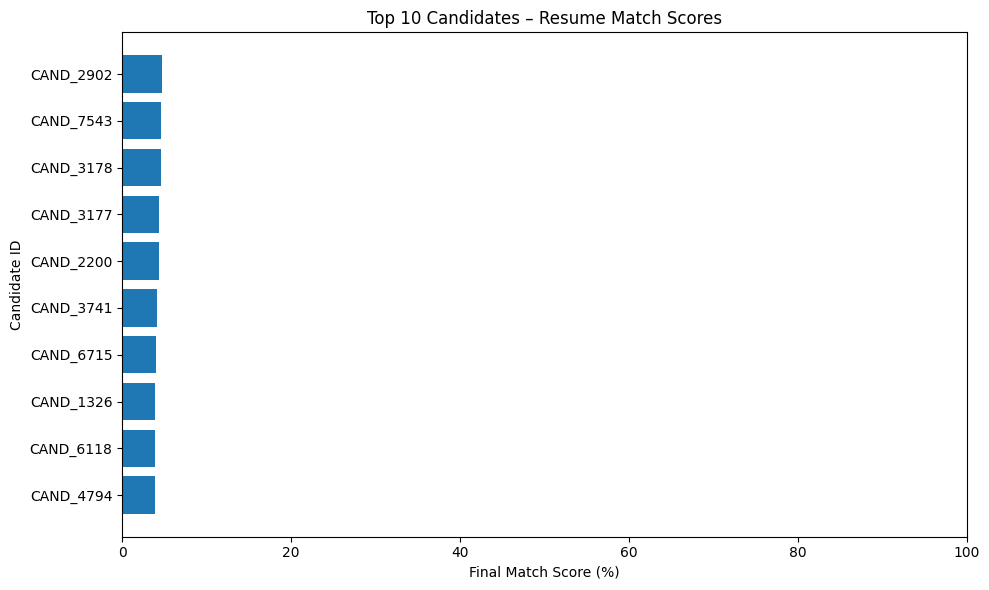

In [28]:
top_candidates = results.head(10).sort_values('final_match_score')

plt.figure(figsize=(10, 6))
plt.barh(top_candidates['candidate_id'], top_candidates['final_match_score'])
plt.xlabel('Final Match Score (%)')
plt.ylabel('Candidate ID')
plt.title('Top 10 Candidates – Resume Match Scores')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## 12. Inspect skill gaps for the top candidates

This table makes the ranking more explainable by showing which required skills were found and which were not detected.

In [29]:
skill_gap_report = results[[
    'rank', 'candidate_id', 'matched_skills', 'missing_skills',
    'skill_match_score', 'final_match_score'
]].copy()

display(skill_gap_report.head(20))

,rank,candidate_id,matched_skills,missing_skills,skill_match_score,final_match_score
0,1,CAND_2902,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,4.725899
1,2,CAND_7543,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,4.582330
2,3,CAND_3178,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,4.546006
3,4,CAND_3177,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,4.394057
4,5,CAND_2200,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,4.355803
5,6,CAND_3741,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,4.172965
6,7,CAND_6715,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,4.027264
7,8,CAND_1326,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,3.879697
8,9,CAND_6118,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,3.873175
9,10,CAND_4794,[],"[excel, machine learning, numpy, pandas, power bi, python, sql, statistics]",0.0,3.852893


## 13. Export results

The CSV file can be used in the Streamlit application or included as a sample output in the project repository. Avoid publishing real, identifiable resumes or candidate data.

In [30]:
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)

export_columns = [
    'rank', 'candidate_id', 'skill_match_score', 'similarity_score',
    'final_match_score', 'matched_skills', 'missing_skills'
]

output_path = output_dir / 'candidate_ranking_results.csv'
results[export_columns].to_csv(output_path, index=False)
print(f'Results exported to: {output_path.resolve()}')

Results exported to: /content/outputs/candidate_ranking_results.csv
